# 07 — Numeric Prediction: Predicting the Room Price (ADR)

**Numeric prediction** models continuous-valued functions: it predicts an unknown numeric target for new data.

**Target:** `adr` — Average Daily Rate (€ per night)

In this notebook:
- Simple linear regression (one feature)
- Multiple linear regression (all features)
- Regression performance: R², RMSE, MAE
- Cross-validation
- Decision tree regression and overfitting

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

BLUE, CYAN, GREEN, ORANGE = "#2563eb", "#06b6d4", "#10b981", "#f97316"
FIG_DIR = Path("../figures")

df = pd.read_csv("../data/processed/hotel_bookings_final.csv")
print(df.shape)

(86620, 41)


## 1. Prepare the Data

Bookings with `adr = 0` are free (complementary) rooms; their price is not set by the market, so they are removed.

In [2]:
print("Bookings with adr = 0:", (df["adr"] == 0).sum())

reg_df = df[df["adr"] > 0].copy()
print(reg_df.shape)
reg_df["adr"].describe().round(1)

Bookings with adr = 0: 1038
(85582, 41)


count    85582.0
mean       108.5
std         50.2
min          0.3
25%         74.5
50%         99.0
75%        135.0
max        510.0
Name: adr, dtype: float64

## 2. Simple Linear Regression

With one input feature, linear regression uses a straight-line equation:

$$\hat{y} = b + wx$$

- $x$: input value · $\hat{y}$: predicted output
- $w$: slope — how much the prediction changes when the input increases by one unit
- $b$: intercept — the prediction when the input is zero

The feature used is `total_guests`, the numeric attribute most related to `adr`.

In [3]:
print(reg_df[["adr", "total_guests", "children", "adults", "lead_time", "total_nights"]].corr()["adr"].round(3))

adr             1.000
total_guests    0.472
children        0.358
adults          0.325
lead_time       0.006
total_nights    0.031
Name: adr, dtype: float64


In [4]:
# Create X from the total_guests column and y from the adr column
X = reg_df["total_guests"].values.reshape(-1, 1)
y = reg_df["adr"].values

# Create and fit the model
reg = LinearRegression()
reg.fit(X, y)

b, w = reg.intercept_, reg.coef_[0]
print(f"b (intercept) = {b:.2f}")
print(f"w (slope)     = {w:.2f}")
print(f"Prediction for 3 guests: {b:.2f} + {w:.2f} × 3 = {b + w * 3:.2f} €")

b (intercept) = 39.51
w (slope)     = 33.95
Prediction for 3 guests: 39.51 + 33.95 × 3 = 141.37 €


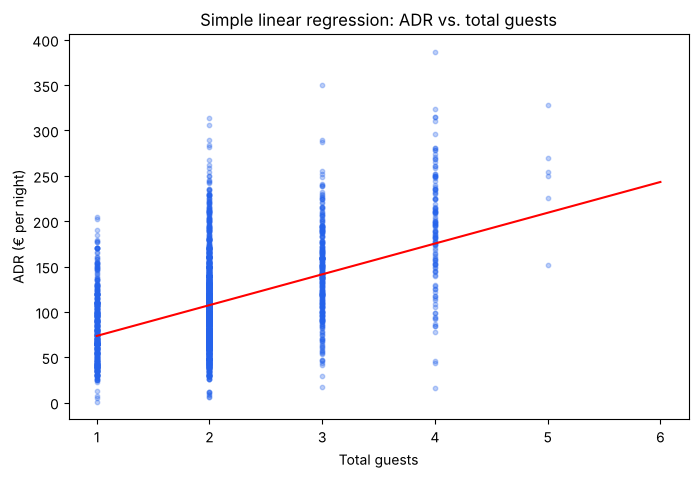

R²: 0.223


In [5]:
sample = reg_df.sample(3000, random_state=42)
x_line = np.arange(1, 7).reshape(-1, 1)

plt.figure(figsize=(8, 5))
plt.scatter(sample["total_guests"], sample["adr"], color=BLUE, alpha=0.3, s=10)
plt.plot(x_line, reg.predict(x_line), color="red")
plt.xlabel("Total guests")
plt.ylabel("ADR (€ per night)")
plt.title("Simple linear regression: ADR vs. total guests")
plt.savefig(FIG_DIR / "reg_01_simple_linear.png", dpi=150, bbox_inches="tight")
plt.show()

print("R²:", round(reg.score(X, y), 3))

## 3. Multiple Linear Regression

With several input features, the model learns a **weight for each feature** and combines their contributions.

During training, **least squares** chooses the weights that minimise the sum of squared differences between
actual and predicted values:

$$L(w, b) = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Only attributes known at booking time are used. `arrival_date_year` and `arrival_date_month` are treated as
categories, because price changes with the season, not in a straight line with the month number.

In [6]:
NUMERIC = ["lead_time", "total_nights", "adults", "children", "babies",
           "total_of_special_requests", "is_repeated_guest", "booking_changes"]
CATEGORICAL = ["hotel", "arrival_date_year", "arrival_date_month", "meal", "market_segment",
               "distribution_channel", "reserved_room_type", "customer_type", "deposit_type"]

# Convert categorical variables to numeric using one-hot encoding
X = pd.get_dummies(reg_df[NUMERIC + CATEGORICAL], columns=CATEGORICAL, drop_first=True, dtype=int)
y = reg_df["adr"]
print(X.shape)

(85582, 49)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate and fit the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)
print("Predictions:", y_pred_lr[:5].round(1))
print("Actual:     ", y_test.values[:5])

Predictions: [143.6 162.4 200.3  89.4  83.1]
Actual:      [129.  221.  207.9  93.6  90.9]


### 3.1 Regression Performance

- **R²:** how much of the variance in `adr` the features explain (1 = perfect)
- **RMSE:** root mean squared error, in € per night
- **MAE:** mean absolute error, in € per night

In [8]:
r2_lr = lr_model.score(X_test, y_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print("R²:  ", round(r2_lr, 4))
print("RMSE:", round(rmse_lr, 2))
print("MAE: ", round(mae_lr, 2))

R²:   0.6386
RMSE: 30.19
MAE:  22.31


### 3.2 Cross-validation for R²

10-fold cross-validation on the training set: each fold is used once for testing and the others for training.

In [9]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = cross_val_score(LinearRegression(), X_train, y_train, cv=kf)

print(cv_scores.round(4))
print("Mean:", round(np.mean(cv_scores), 4))
print("Standard deviation:", round(np.std(cv_scores), 4))
print("95% interval:", np.quantile(cv_scores, [0.025, 0.975]).round(4))

[0.6506 0.6323 0.6369 0.6517 0.6488 0.6406 0.667  0.6448 0.6448 0.6343]
Mean: 0.6452
Standard deviation: 0.0097
95% interval: [0.6327 0.6636]


### 3.3 Weights of the Months

Each weight shows how much the predicted price changes compared with the baseline month (**April**),
when all other features stay the same.

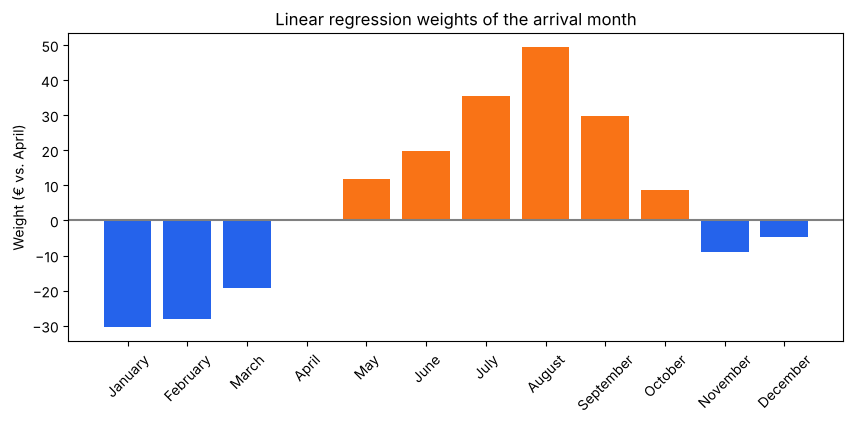

January     -30.5
February    -28.1
March       -19.3
April         0.0
May          11.8
June         19.7
July         35.6
August       49.3
September    29.7
October       8.8
November     -8.9
December     -4.8
dtype: float64

In [10]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

weights = pd.Series(lr_model.coef_, index=X.columns)
month_w = pd.Series({m: weights.get(f"arrival_date_month_{m}", 0.0) for m in months})

plt.figure(figsize=(10, 4))
plt.bar(month_w.index, month_w.values, color=[ORANGE if v > 0 else BLUE for v in month_w.values])
plt.axhline(0, color="grey")
plt.ylabel("Weight (€ vs. April)")
plt.title("Linear regression weights of the arrival month")
plt.xticks(rotation=45)
plt.savefig(FIG_DIR / "reg_02_month_weights.png", dpi=150, bbox_inches="tight")
plt.show()

month_w.round(1)

## 4. Decision Tree Regression

A regression tree splits the data like a classification tree, but each leaf predicts the **average** `adr`
of its training records.

### 4.1 A tree without limits: training vs. test error (RMSE)

- **Underfitting:** high error on both training and test sets
- **Overfitting:** low training error, high test error

In [11]:
tree_full = DecisionTreeRegressor(random_state=42)
tree_full.fit(X_train, y_train)

print("Depth:", tree_full.get_depth())
print("Training RMSE:", round(np.sqrt(mean_squared_error(y_train, tree_full.predict(X_train))), 2))
print("Test RMSE:    ", round(np.sqrt(mean_squared_error(y_test, tree_full.predict(X_test))), 2))

Depth: 50
Training RMSE: 4.11
Test RMSE:     26.14


### 4.2 Choosing the depth with cross-validation

In [12]:
cv_rmse_depths = {}
for depth in range(2, 25, 2):
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_squared_error")
    cv_rmse_depths[depth] = round(float(np.sqrt(-scores.mean())), 2)

best_depth = min(cv_rmse_depths, key=cv_rmse_depths.get)
print(cv_rmse_depths)
print("Best depth:", best_depth)

{2: 43.75, 4: 38.67, 6: 32.75, 8: 29.58, 10: 27.17, 12: 25.91, 14: 24.97, 16: 24.63, 18: 24.8, 20: 24.77, 22: 25.14, 24: 25.24}
Best depth: 16


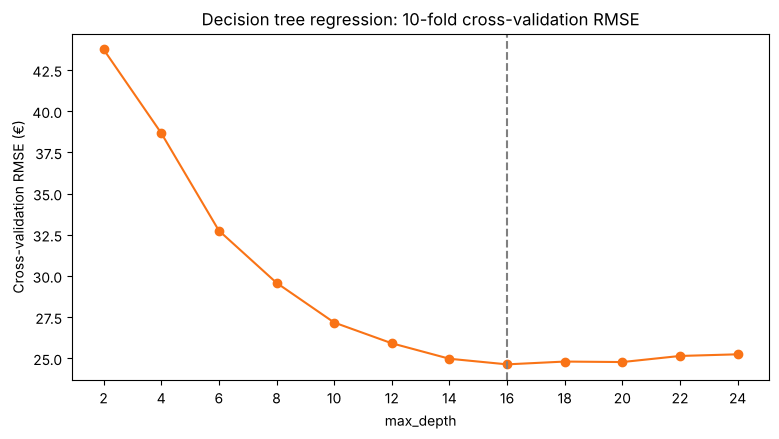

In [13]:
plt.figure(figsize=(9, 4.5))
plt.plot(list(cv_rmse_depths.keys()), list(cv_rmse_depths.values()), marker="o", color=ORANGE)
plt.axvline(best_depth, color="grey", ls="--")
plt.xlabel("max_depth")
plt.ylabel("Cross-validation RMSE (€)")
plt.title("Decision tree regression: 10-fold cross-validation RMSE")
plt.xticks(list(cv_rmse_depths.keys()))
plt.savefig(FIG_DIR / "reg_03_tree_depth.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Final Decision Tree Regressor

In [14]:
dtr_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
dtr_model.fit(X_train, y_train)
y_pred_dtr = dtr_model.predict(X_test)

r2_dtr = dtr_model.score(X_test, y_test)
rmse_dtr = np.sqrt(mean_squared_error(y_test, y_pred_dtr))
mae_dtr = mean_absolute_error(y_test, y_pred_dtr)

print("Training RMSE:", round(np.sqrt(mean_squared_error(y_train, dtr_model.predict(X_train))), 2))
print("Test RMSE:    ", round(rmse_dtr, 2))

Training RMSE: 17.37
Test RMSE:     24.93


## 5. Comparing the Two Models

In [15]:
comparison = pd.DataFrame({"Linear Regression": [r2_lr, rmse_lr, mae_lr],
                           "Decision Tree Regression": [r2_dtr, rmse_dtr, mae_dtr]},
                          index=["R²", "RMSE (€)", "MAE (€)"])
comparison.round(3)

,Linear Regression,Decision Tree Regression
R²,0.639,0.754
RMSE (€),30.185,24.928
MAE (€),22.308,15.830


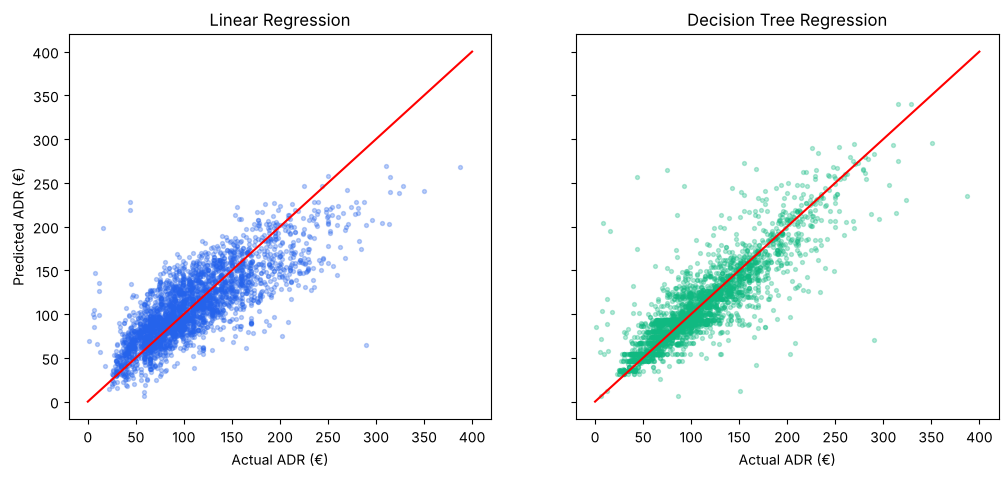

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, pred, name, color in [(axes[0], y_pred_lr, "Linear Regression", BLUE),
                              (axes[1], y_pred_dtr, "Decision Tree Regression", GREEN)]:
    ax.scatter(y_test[:3000], pred[:3000], s=8, alpha=0.3, color=color)
    ax.plot([0, 400], [0, 400], color="red")
    ax.set_title(name)
    ax.set_xlabel("Actual ADR (€)")
axes[0].set_ylabel("Predicted ADR (€)")
plt.savefig(FIG_DIR / "reg_04_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Summary

**Question:** How much of the room price (ADR) can be predicted from attributes known at booking time?

| | Linear Regression | Decision Tree Regression |
|---|---|---|
| Setting | all 49 features | max_depth = 16 (10-fold cross-validation) |
| R² | 0.639 | **0.754** |
| RMSE | €30.2 | **€24.9** |
| MAE | €22.3 | **€15.8** |

**Findings**
1. With one feature, `total_guests` explains 22% of the variance (ŷ = 39.5 + 34.0 × guests): each extra guest adds about €34 per night.
2. Multiple linear regression explains **64%** of the variance; 10-fold cross-validation gives the same result (0.645 ± 0.010), so the model is stable.
3. **Seasonality:** compared with April, August is about **+€49** per night and January about **−€31**, with all other features held the same.
4. A decision tree without limits overfits (training RMSE €4.1, test RMSE €26.1). With max_depth = 16 it explains **75.4%** of the variance — better than linear regression, because price does not change in a straight line with the attributes.

**Limitation:** about a quarter of the variance remains unexplained; the exact room, daily demand and promotions are not in the data.